In [ ]:
# SEL 1 - Konfigurasi eksperimen, impor, dan folder hasil
import os
import sys
import json
import random
import pickle
import hashlib
import warnings
from pathlib import Path
from datetime import datetime, timezone
from uuid import uuid4
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    roc_curve, precision_recall_curve,
)

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')

BASE = Path(os.environ.get('TIAT_DATA_DIR', '/content/drive/MyDrive/dataset'))
OUTPUT_ROOT = Path(os.environ.get('TIAT_OUTPUT_DIR', str(BASE / 'processed_tiat_review_v2')))
RUN_DIR = OUTPUT_ROOT / (datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid4().hex[:8])
RUN_DIR.mkdir(parents=True, exist_ok=False)
FILES = [BASE / name for name in [
    'log_standard_4_08_to_4_21_27k_part1.csv',
    'log_standard_4_08_to_4_21_27k_part2.csv',
    'log_standard_4_22_to_5_08_27k_part1.csv',
    'log_standard_4_22_to_5_08_27k_part2.csv',
]]
CONFIG = {
    'protocol': 'tiat_historical_disjoint_actual_time_v2',
    'use_all_users': True,
    'data_seed': 42,
    'train_seeds': [42, 123, 2026],
    'window_size': 10,
    'window_step': 10,
    'seq_len': 8,
    'min_history': 100,
    'k_hie': 1.5,
    'train_fraction_time': 0.70,
    'val_fraction_time': 0.15,
    'train_end_ms': None,  # opsional cutoff eksklusif yang ditetapkan sebelumnya
    'val_end_ms': None,
    # Tidak ada pembatas jumlah sequence: semua contoh valid digunakan.
    'max_train_samples': None,
    'max_val_samples': None,
    'max_test_samples': None,
    'array_chunk_samples': 25_000,  # batch pengisian array ke disk
    'd_model': 32, 'n_heads': 4, 'n_layers': 1, 'ff_dim': 64,
    'dropout': 0.1, 'batch_size': 256, 'eval_batch_size': 1024,
    'epochs': 30, 'early_stopping_patience': 7,
    'lr': 1e-3, 'weight_decay': 1e-4,
    'time_scale_seconds': 60.0,
    'classification_threshold': 0.5,
    'bootstrap_reps': 500,
    'csv_chunk_size': 100_000,
}
SIGNALS = ['is_like', 'is_comment', 'is_forward', 'is_hate']
REQUIRED = ['user_id', 'video_id', 'time_ms', 'play_time_ms'] + SIGNALS
FEATURES = ['n_total', 'n_like', 'n_comment', 'n_forward',
            'n_hate', 'avg_play_ms', 'rasio_like']
HOUR_MS = 3_600_000
SPLITS = ('train', 'val', 'test')
assert CONFIG['window_step'] == CONFIG['window_size']
assert CONFIG['min_history'] >= 2
print('Folder hasil:', RUN_DIR)
print(json.dumps(CONFIG, indent=2))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder hasil: /content/drive/MyDrive/dataset/processed_tiat_review_v2/20261118T181035Z_71d30f19
{
  "protocol": "tiat_historical_disjoint_actual_time_v2",
  "use_all_users": true,
  "data_seed": 42,
  "train_seeds": [
    42,
    123,
    2026
  ],
  "window_size": 10,
  "window_step": 10,
  "seq_len": 8,
  "min_history": 100,
  "k_hie": 1.5,
  "train_fraction_time": 0.7,
  "val_fraction_time": 0.15,
  "train_end_ms": null,
  "val_end_ms": null,
  "max_train_samples": null,
  "max_val_samples": null,
  "max_test_samples": null,
  "array_chunk_samples": 25000,
  "d_model": 32,
  "n_heads": 4,
  "n_layers": 1,
  "ff_dim": 64,
  "dropout": 0.1,
  "batch_size": 256,
  "eval_batch_size": 1024,
  "epochs": 30,
  "early_stopping_patience": 7,
  "lr": 0.001,
  "weight_decay": 0.0001,
  "time_scale_seconds": 60.0,
  "classification_threshold": 0.5,
  "bootstrap_reps":

In [ ]:
# SEL 2 - Manifest sumber data dan batas waktu train, validasi, dan test
def scan_sources(files, config):
    first_seen = pd.Series(dtype='int64')
    minimum, maximum = None, None
    manifest = []
    for path in files:
        if not path.is_file():
            raise FileNotFoundError(f'CSV tidak ditemukan: {path}. Periksa BASE pada SEL 1.')
        columns = pd.read_csv(path, nrows=0).columns.tolist()
        missing = sorted(set(REQUIRED) - set(columns))
        if missing:
            raise ValueError(f'{path.name}: kolom wajib tidak ada: {missing}. Gunakan log asli dengan time_ms.')
        stat = path.stat()
        manifest.append({'path': str(path), 'bytes': stat.st_size,
                         'mtime_ns': stat.st_mtime_ns, 'columns': columns})
        for chunk in pd.read_csv(path, usecols=['user_id', 'time_ms'],
                                 chunksize=config['csv_chunk_size']):
            chunk = chunk.apply(pd.to_numeric, errors='coerce')
            chunk = chunk.replace([np.inf, -np.inf], np.nan).dropna()
            chunk = chunk[(chunk['time_ms'] > 0) &
                          (chunk['time_ms'] % 1 == 0) & (chunk['user_id'] % 1 == 0)]
            if chunk.empty:
                continue
            chunk = chunk.astype('int64')
            current = chunk.groupby('user_id')['time_ms'].min()
            first_seen = pd.concat([first_seen, current]).groupby(level=0).min().astype('int64')
            lo, hi = int(chunk.time_ms.min()), int(chunk.time_ms.max())
            minimum = lo if minimum is None else min(minimum, lo)
            maximum = hi if maximum is None else max(maximum, hi)
        print('Selesai scan:', path.name)
    if minimum is None or maximum <= minimum:
        raise ValueError('Rentang timestamp tidak memadai.')
    begin = (minimum // HOUR_MS) * HOUR_MS
    end = (maximum // HOUR_MS + 1) * HOUR_MS
    span = end - begin
    c1 = config['train_end_ms']
    c2 = config['val_end_ms']
    if c1 is None:
        c1 = int((begin + config['train_fraction_time'] * span) // HOUR_MS) * HOUR_MS
    if c2 is None:
        c2 = int((begin + (config['train_fraction_time'] + config['val_fraction_time']) * span) // HOUR_MS) * HOUR_MS
    c1, c2 = int(c1), int(c2)
    if not (minimum < c1 < c2 <= maximum) or c1 % HOUR_MS or c2 % HOUR_MS:
        raise ValueError('Cutoff harus berurutan, berada dalam data, dan tepat pada batas jam UTC.')
    all_users = np.sort(first_seen.index.to_numpy(dtype=np.int64))
    if not len(all_users):
        raise ValueError('Tidak ada pengguna dengan ID dan timestamp yang valid.')
    early_users = int((first_seen < c1).sum())
    print('Semua pengguna teramati:', len(all_users),
          '| pertama muncul sebelum cutoff train:', early_users,
          '| baru pada val/test:', len(all_users) - early_users)
    return all_users, (c1, c2), manifest

ALL_USER_IDS, CUTOFFS, SOURCE_MANIFEST = scan_sources(FILES, CONFIG)
pd.Series(ALL_USER_IDS, name='user_id').to_csv(RUN_DIR / 'all_users_observed.csv', index=False)
with open(RUN_DIR / 'protocol.json', 'w') as f:
    json.dump({'config': CONFIG, 'cutoffs_ms': CUTOFFS, 'sources': SOURCE_MANIFEST,
               'user_selection': 'ALL observed user IDs, no random selection',
               'all_users_observed_count': len(ALL_USER_IDS)}, f, indent=2)
print('Pengguna ditemukan (tanpa sampling):', len(ALL_USER_IDS))
print('Train berakhir / validasi dimulai:', pd.to_datetime(CUTOFFS[0], unit='ms', utc=True))
print('Validasi berakhir / test dimulai:', pd.to_datetime(CUTOFFS[1], unit='ms', utc=True))

Selesai scan: log_standard_4_08_to_4_21_27k_part1.csv
Selesai scan: log_standard_4_08_to_4_21_27k_part2.csv
Selesai scan: log_standard_4_22_to_5_08_27k_part1.csv
Selesai scan: log_standard_4_22_to_5_08_27k_part2.csv
Semua pengguna teramati: 27285 | pertama muncul sebelum cutoff train: 27106 | baru pada val/test: 179
Pengguna ditemukan (tanpa sampling): 27285
Train berakhir / validasi dimulai: 2022-04-29 07:00:00+00:00
Validasi berakhir / test dimulai: 2022-05-03 23:00:00+00:00


In [ ]:
# SEL 3 - Preprocessing interaksi dan perhitungan riwayat per pengguna
import gc
import tempfile
import shutil
import importlib.util
import subprocess

if importlib.util.find_spec('pyarrow') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'pyarrow'])

# Simpan file sementara di disk LOCAL Colab, bukan RAM / Google Drive.
STAGE3_DIR = Path(tempfile.mkdtemp(prefix='tiat_preprocess_', dir='/content'))
BUCKET_DIR = STAGE3_DIR / 'buckets'
CLEAN_DIR = STAGE3_DIR / 'clean'
OUT_DIR = RUN_DIR / 'interactions_parts'
for folder in (BUCKET_DIR, CLEAN_DIR, OUT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

N_BUCKETS = 256  # kelompok lebih kecil untuk seluruh pengguna
print('Sisa disk lokal (GB):', round(shutil.disk_usage('/content').free / (1024 ** 3), 2))
print('Jika disk lokal penuh, perlu runtime dengan disk lebih besar / staging alternatif.')
READ_CHUNK = min(int(CONFIG['csv_chunk_size']), 100_000)
# Semua pengguna digunakan. Tidak ada filtering berdasarkan daftar user.
INT_COLS = ['user_id', 'video_id', 'time_ms']
RAW_DTYPES = {'user_id': 'int64', 'video_id': 'int64', 'time_ms': 'int64',
              'play_time_ms': 'float64', **{c: 'int8' for c in SIGNALS}}


def clean_chunk_selected(frame):
    # Deduplikasi per bucket pada tahap berikutnya juga mencakup duplikat lintas file.
    frame = frame[REQUIRED].copy()
    for col in REQUIRED:
        frame[col] = pd.to_numeric(frame[col], errors='coerce')
    frame = frame.replace([np.inf, -np.inf], np.nan).dropna(subset=REQUIRED)
    frame = frame[(frame['play_time_ms'] > 0) & (frame['time_ms'] > 0)]
    for col in INT_COLS:
        frame = frame[frame[col] % 1 == 0]
    for col in SIGNALS:
        frame = frame[frame[col].isin([0, 1])]
    if frame.empty:
        return frame
    for col in INT_COLS:
        frame[col] = frame[col].astype('int64')
    for col in SIGNALS:
        frame[col] = frame[col].astype('int8')
    frame['play_time_ms'] = frame['play_time_ms'].astype('float64')
    return frame


# TAHAP A: Membaca CSV bertahap, tanpa parts.append(...)
before = valid_rows = 0
for path in FILES:
    for chunk in pd.read_csv(path, usecols=REQUIRED, chunksize=READ_CHUNK):
        before += len(chunk)
        cleaned = clean_chunk_selected(chunk)
        valid_rows += len(cleaned)
        if cleaned.empty:
            continue
        cleaned['_bucket'] = (cleaned['user_id'] % N_BUCKETS).astype('int16')
        for b, batch in cleaned.groupby('_bucket', sort=False):
            bucket_path = BUCKET_DIR / f'bucket_{int(b):03d}.csv'
            exists = bucket_path.exists()
            batch[REQUIRED].to_csv(bucket_path, index=False, mode='a',
                                   header=not exists, float_format='%.17g')
        del cleaned, chunk
    gc.collect()
    print('Selesai membaca:', path.name)

if valid_rows == 0:
    raise ValueError('Tidak ada interaksi valid dalam sumber CSV.')

# TAHAP B: Deduplikasi persis, audit collision, urutkan per pengguna.
counts_by_user = {}
exact_removed = final_rows = collision_groups = collision_records = 0
examples_saved = 0
summary_csv = RUN_DIR / 'audit_event_key_collisions_summary.csv'
examples_csv = RUN_DIR / 'audit_event_key_collisions_examples.csv'
EVENT_KEY = ['user_id', 'video_id', 'time_ms']

for csv_path in sorted(BUCKET_DIR.glob('bucket_*.csv')):
    df = pd.read_csv(csv_path, dtype=RAW_DTYPES)
    n_before = len(df)
    df = df.drop_duplicates(subset=REQUIRED).copy()
    exact_removed += n_before - len(df)
    if df.empty:
        continue
    collision = df.duplicated(subset=EVENT_KEY, keep=False)
    if collision.any():
        repeated = df.loc[collision, REQUIRED].sort_values(
            EVENT_KEY + ['play_time_ms'], kind='mergesort')
        audit = repeated.groupby(EVENT_KEY, sort=False).agg(
            record_count=('play_time_ms', 'size'),
            distinct_play_times=('play_time_ms', 'nunique'),
            distinct_likes=('is_like', 'nunique'),
            distinct_comments=('is_comment', 'nunique'),
            distinct_forwards=('is_forward', 'nunique'),
            distinct_hates=('is_hate', 'nunique')).reset_index()
        audit.to_csv(summary_csv, mode='a', index=False,
                     header=not summary_csv.exists())
        if examples_saved < 1000:
            sample = repeated.head(1000 - examples_saved)
            sample.to_csv(examples_csv, mode='a', index=False,
                          header=not examples_csv.exists())
            examples_saved += len(sample)
        collision_groups += len(audit)
        collision_records += len(repeated)
        del repeated, audit
    df = df.sort_values(['user_id', 'time_ms', 'video_id', 'play_time_ms'],
                        kind='mergesort').reset_index(drop=True)
    final_rows += len(df)
    counts_by_user.update({int(uid): int(n) for uid, n in
                           df.groupby('user_id', sort=False).size().items()})
    df.to_parquet(CLEAN_DIR / f'{csv_path.stem}.parquet', index=False)
    del df
    gc.collect()

if not counts_by_user:
    raise ValueError('Semua observasi terhapus pada preprocessing.')

# event_id tetap unik, berurutan, dan identik dengan global sort user_id/time_ms.
user_offsets = {}
position = 0
for uid in sorted(counts_by_user):
    user_offsets[uid] = position
    position += counts_by_user[uid]
assert position == final_rows

# TAHAP C: Statistik historis, diselesaikan per bucket (bukan satu DataFrame raksasa).
RAW_PARTS = []
for parquet_path in sorted(CLEAN_DIR.glob('bucket_*.parquet')):
    df = pd.read_parquet(parquet_path)
    df['user_rank'] = df.groupby('user_id', sort=False).cumcount().astype('int64')
    df['event_id'] = (df['user_rank'] + df['user_id'].map(user_offsets)).astype('int64')
    df['hour_block'] = (df['time_ms'] // HOUR_MS).astype('int64')
    c1, c2 = CUTOFFS
    df['split'] = np.select([df.time_ms < c1, df.time_ms < c2],
                            ['train', 'val'], default='test')
    df['intensity'] = (
        df.play_time_ms / 1000.0 + 5.0 * df.is_like + 10.0 * df.is_comment
        + 8.0 * df.is_forward - 3.0 * df.is_hate).clip(lower=0)
    if not np.isfinite(df.intensity.to_numpy()).all():
        raise ValueError('Intensity tidak finite.')

    n = len(df)
    history_n = np.zeros(n, dtype='int64')
    history_mean = np.full(n, np.nan, dtype='float64')
    history_std = np.full(n, np.nan, dtype='float64')
    for _, g in df.groupby('user_id', sort=False):
        idx = g.index.to_numpy(dtype='int64')
        ts = g['time_ms'].to_numpy(dtype='int64')
        intens = g['intensity'].reset_index(drop=True).astype('float64')
        past = np.searchsorted(ts, ts, side='left')
        mu = intens.expanding(min_periods=CONFIG['min_history']).mean().shift(1).to_numpy()
        sd = intens.expanding(min_periods=CONFIG['min_history']).std(ddof=1).shift(1).to_numpy()
        history_n[idx] = past
        history_mean[idx] = mu[past]
        history_std[idx] = sd[past]
    df['history_n'] = history_n
    df['history_mean'] = history_mean
    df['history_std'] = history_std
    df['threshold_before'] = history_mean + CONFIG['k_hie'] * history_std

    part_path = OUT_DIR / parquet_path.name
    df.to_parquet(part_path, index=False)
    RAW_PARTS.append(part_path)
    print('Historis selesai:', parquet_path.name, '| observasi:', f'{len(df):,}')
    del df
    gc.collect()

# File raw didistribusikan ke part Parquet; JANGAN muat semuanya sebagai `raw`.
print(f'Raw seluruh pengguna: {before:,}; valid: {valid_rows:,}; '
      f'duplikat eksak dihapus: {exact_removed:,}; akhir: {final_rows:,}')
print(f'AUDIT: {collision_groups:,} kombinasi key dengan '
      f'{collision_records:,} rekaman berbeda; seluruhnya dipertahankan.')
print('Jumlah part Parquet:', len(RAW_PARTS))

# Ringkasan train/val/test tanpa memuat seluruh dataset.
split_counts = {name: {'events': 0, 'users': set()} for name in SPLITS}
for part_path in RAW_PARTS:
    tmp = pd.read_parquet(part_path, columns=['user_id', 'split'])
    for name, g in tmp.groupby('split', sort=False):
        split_counts[name]['events'] += len(g)
        split_counts[name]['users'].update(map(int, g.user_id.unique()))
    del tmp
print(pd.DataFrame({k: {'events': v['events'], 'users': len(v['users'])}
                    for k, v in split_counts.items()}).T)

# Hapus CSV dan Parquet sementara, hanya jika seluruh proses sukses.
shutil.rmtree(STAGE3_DIR)
print('Selesai. Data tersimpan di:', OUT_DIR)

Sisa disk lokal (GB): 81.27
Jika disk lokal penuh, perlu runtime dengan disk lebih besar / staging alternatif.
Selesai membaca: log_standard_4_08_to_4_21_27k_part1.csv
Selesai membaca: log_standard_4_08_to_4_21_27k_part2.csv
Selesai membaca: log_standard_4_22_to_5_08_27k_part1.csv
Selesai membaca: log_standard_4_22_to_5_08_27k_part2.csv
Historis selesai: bucket_000.parquet | observasi: 1,129,554
Historis selesai: bucket_001.parquet | observasi: 1,123,498
Historis selesai: bucket_002.parquet | observasi: 1,034,263
Historis selesai: bucket_003.parquet | observasi: 1,016,471
Historis selesai: bucket_004.parquet | observasi: 1,122,558
Historis selesai: bucket_005.parquet | observasi: 938,887
Historis selesai: bucket_006.parquet | observasi: 1,007,782
Historis selesai: bucket_007.parquet | observasi: 1,077,336
Historis selesai: bucket_008.parquet | observasi: 955,671
Historis selesai: bucket_009.parquet | observasi: 1,083,784
Historis selesai: bucket_010.parquet | observasi: 1,058,863
Histo

In [ ]:
# SEL 4 - Pembentukan window dan label HIE
def make_windows_from_parts(raw_parts, config):
    width = config['window_size']
    if config['window_step'] != width:
        raise ValueError('Implementasi revisi ini mensyaratkan non-overlapping windows.')
    windows_dir = RUN_DIR / 'window_parts'
    windows_dir.mkdir(parents=True, exist_ok=True)
    window_part_paths = []
    for source_path in raw_parts:
        raw_piece = pd.read_parquet(source_path)
        pieces = []
        for (uid, split, hour), g in raw_piece.groupby(
                ['user_id', 'split', 'hour_block'], sort=False):
            g = g.sort_values(['time_ms', 'video_id'], kind='mergesort')
            count = len(g) // width
            if count == 0:
                continue
            g = g.iloc[:count * width]
            def matrix(col):
                return g[col].to_numpy().reshape(count, width)
            threshold = matrix('threshold_before')[:, 0]
            maximum = matrix('intensity').max(axis=1)
            enough = (np.isfinite(threshold) &
                      (matrix('history_n')[:, 0] >= config['min_history']))
            labels = np.where(enough, (maximum > threshold).astype(np.int8), -1)
            likes = matrix('is_like').sum(axis=1)
            pieces.append(pd.DataFrame({
                'user_id': uid, 'split': split, 'hour_block': hour,
                'window_order': np.arange(count),
                'event_start': matrix('event_id')[:, 0],
                'event_end': matrix('event_id')[:, -1],
                'rank_start': matrix('user_rank')[:, 0],
                'rank_end': matrix('user_rank')[:, -1],
                'time_start_ms': matrix('time_ms')[:, 0],
                'time_end_ms': matrix('time_ms')[:, -1],
                'n_total': width, 'n_like': likes,
                'n_comment': matrix('is_comment').sum(axis=1),
                'n_forward': matrix('is_forward').sum(axis=1),
                'n_hate': matrix('is_hate').sum(axis=1),
                'avg_play_ms': matrix('play_time_ms').mean(axis=1),
                'rasio_like': likes / width,
                'history_n': matrix('history_n')[:, 0],
                'threshold_before': threshold,
                'max_intensity': maximum,
                'label': labels,
            }))
        del raw_piece
        if pieces:
            output = windows_dir / source_path.name
            pd.concat(pieces, ignore_index=True).to_parquet(output, index=False)
            window_part_paths.append(output)
        del pieces
        gc.collect()
        print('Window selesai:', source_path.name)
    if not window_part_paths:
        raise ValueError('Tidak ada window lengkap.')
    # Data window jauh lebih kecil dari raw; dibutuhkan untuk SEL 6.
    windows = pd.concat((pd.read_parquet(p) for p in window_part_paths),
                        ignore_index=True)
    return windows

windows = make_windows_from_parts(RAW_PARTS, CONFIG)
windows.to_parquet(RUN_DIR / 'windows.parquet', index=False)
# Hemat RAM untuk audit dan penyusunan sequence.
windows['split'] = windows['split'].astype('category')
print('Window:', len(windows), '| pengguna:', windows.user_id.nunique())

Window selesai: bucket_000.parquet
Window selesai: bucket_001.parquet
Window selesai: bucket_002.parquet
Window selesai: bucket_003.parquet
Window selesai: bucket_004.parquet
Window selesai: bucket_005.parquet
Window selesai: bucket_006.parquet
Window selesai: bucket_007.parquet
Window selesai: bucket_008.parquet
Window selesai: bucket_009.parquet
Window selesai: bucket_010.parquet
Window selesai: bucket_011.parquet
Window selesai: bucket_012.parquet
Window selesai: bucket_013.parquet
Window selesai: bucket_014.parquet
Window selesai: bucket_015.parquet
Window selesai: bucket_016.parquet
Window selesai: bucket_017.parquet
Window selesai: bucket_018.parquet
Window selesai: bucket_019.parquet
Window selesai: bucket_020.parquet
Window selesai: bucket_021.parquet
Window selesai: bucket_022.parquet
Window selesai: bucket_023.parquet
Window selesai: bucket_024.parquet
Window selesai: bucket_025.parquet
Window selesai: bucket_026.parquet
Window selesai: bucket_027.parquet
Window selesai: buck

In [ ]:
# SEL 5 - Audit pemisahan waktu dan ringkasan window

def audit_windows_from_parts(raw_parts, windows, cutoffs, config):
    c1, c2 = cutoffs
    split_seen = {name: False for name in SPLITS}
    for p in raw_parts:
        r = pd.read_parquet(p, columns=['user_id','split','hour_block','time_ms'])
        for name, low, high in [('train', -np.inf, c1),
                                ('val', c1, c2), ('test', c2, np.inf)]:
            current = r.loc[r.split == name, 'time_ms']
            if len(current):
                split_seen[name] = True
                assert current.min() >= low and current.max() < high
        assert r.groupby(['user_id', 'hour_block'])['split'].nunique().max() == 1
        del r
    for name, low, high in [('train', -np.inf, c1),
                            ('val', c1, c2), ('test', c2, np.inf)]:
        w = windows[windows.split == name]
        if not split_seen[name] or w.empty:
            raise ValueError(f'Partisi {name} tidak mempunyai raw/window yang cukup.')
        assert w.time_start_ms.min() >= low and w.time_end_ms.max() < high
    assert (windows.rank_end - windows.rank_start + 1 == config['window_size']).all()
    for _, g in windows.groupby(['user_id', 'split', 'hour_block'], sort=False):
        assert np.all(g.event_start.to_numpy()[1:] > g.event_end.to_numpy()[:-1])
    print('PASS: cutoff kronologis, partisi terpisah, dan window non-overlap.')


audit_windows_from_parts(RAW_PARTS, windows, CUTOFFS, CONFIG)
window_summary = windows.groupby('split').agg(
    windows=('label','size'),
    eligible_targets=('label', lambda s: int((s >= 0).sum())),
    HIE=('label', lambda s: int((s == 1).sum())),
    users=('user_id','nunique'))
window_summary['HIE_rate_eligible'] = (window_summary.HIE /
                                      window_summary.eligible_targets)
window_summary.to_csv(RUN_DIR / 'window_summary.csv')
print(window_summary)

/tmp/ipykernel_43609/588062194.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for _, g in windows.groupby(['user_id', 'split', 'hour_block'], sort=False):


PASS: cutoff kronologis, partisi terpisah, dan window non-overlap.


/tmp/ipykernel_43609/588062194.py:29: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  window_summary = windows.groupby('split').agg(


        windows  eligible_targets      HIE  users  HIE_rate_eligible
split                                                               
test    3865448           3864756  1387520  26815           0.359019
train  15213506          14975744  5533214  27013           0.369478
val     4145886           4143755  1456722  26880           0.351546


In [ ]:
# SEL 6 - Indeks sequence dan array X, T, y untuk setiap partisi
import gc
import json
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq


def build_sequences_streaming(windows, config, run_dir, features, splits=('train', 'val', 'test')):
    length = int(config['seq_len'])
    chunk_size = int(config['array_chunk_samples'])
    n_windows = len(windows)
    if n_windows <= length:
        raise ValueError('Jumlah window tidak cukup untuk membentuk sequence.')
    for name in splits:
        if config[f'max_{name}_samples'] is not None:
            raise ValueError('Mode all-sequences memerlukan max_*_samples = None.')

    array_dir = Path('/content') / ('tiat_arrays_' + run_dir.name)
    array_dir.mkdir(parents=True, exist_ok=True)
    index_paths = {'all': run_dir / 'sample_index_all.parquet'}
    index_paths.update({name: run_dir / f'sample_index_{name}.parquet' for name in splits})
    partial_paths = {name: p.with_suffix('.partial.parquet') for name, p in index_paths.items()}
    array_paths = {name: {
        'X': array_dir / f'{name}_raw_X.npy',
        'T': array_dir / f'{name}_T.npy',
        'y': array_dir / f'{name}_y.npy',
    } for name in splits}
    protected = (list(index_paths.values()) + list(partial_paths.values()) +
                 [p for block in array_paths.values() for p in block.values()])
    existing = [p for p in protected if p.exists()]
    if existing:
        raise FileExistsError('Ada output SEL 6 yang sudah ada; periksa sebelum mengulang: '
                              + ', '.join(map(str, existing[:5])))

    users = windows['user_id'].to_numpy(copy=False)
    hours = windows['hour_block'].to_numpy(copy=False)
    split_series = windows['split'].astype('category')
    categories = split_series.cat.categories
    codes = split_series.cat.codes.to_numpy(copy=False)
    split_codes = {name: int(categories.get_loc(name)) for name in splits}
    starts_event = windows['event_start'].to_numpy(copy=False)
    ends_event = windows['event_end'].to_numpy(copy=False)
    starts_time = windows['time_start_ms'].to_numpy(copy=False)
    ends_time = windows['time_end_ms'].to_numpy(copy=False)
    labels = windows['label'].to_numpy(copy=False)

    # Semua window dari satu user/split/jam tersusun berdampingan dalam hasil SEL 4.
    boundary = np.empty(n_windows, dtype=np.bool_)
    boundary[0] = True
    boundary[1:] = ((users[1:] != users[:-1]) |
                    (hours[1:] != hours[:-1]) |
                    (codes[1:] != codes[:-1]))
    block_ids = np.cumsum(boundary, dtype=np.int32)
    del boundary

    def valid_pairs():
        # Ukuran blok terbatas; tidak membuat jutaan DataFrame kecil.
        for begin in range(0, n_windows - length, chunk_size):
            s = np.arange(begin, min(begin + chunk_size, n_windows - length), dtype=np.int64)
            target = s + length
            last = target - 1
            ok = ((block_ids[s] == block_ids[target]) & (labels[target] >= 0) &
                  (ends_event[last] < starts_event[target]) &
                  (ends_time[last] < starts_time[target]))
            if ok.any():
                yield s[ok], target[ok]

    # PASS 1: hitung sampel valid per partisi untuk ukuran memmap yang tepat.
    counts = {name: 0 for name in splits}
    positives = {name: 0 for name in splits}
    users_by_split = {name: set() for name in splits}
    for s, target in valid_pairs():
        for name, code in split_codes.items():
            chosen = target[codes[target] == code]
            counts[name] += len(chosen)
            positives[name] += int(np.count_nonzero(labels[chosen] == 1))
            users_by_split[name].update(map(int, np.unique(users[chosen])))
    if any(counts[name] == 0 for name in splits):
        raise ValueError(f'Ada partisi tanpa sampel valid: {counts}')

    total = sum(counts.values())
    estimated_bytes = total * (length * len(features) + length + 1) * 4
    # SEL 7 juga akan membuat scaled_X. Periksa kebutuhan kedua tahap.
    scaled_bytes = total * length * len(features) * 4
    free_bytes = shutil.disk_usage('/content').free
    print('Sequence valid per split:', counts)
    print('HIE per split:', positives)
    print('Total sequence:', f'{total:,}')
    print('Estimasi array SEL 6 + SEL 7 (GB):', round((estimated_bytes + scaled_bytes) / 1024**3, 2))
    print('Disk lokal tersedia (GB):', round(free_bytes / 1024**3, 2))
    if estimated_bytes + scaled_bytes + 2 * 1024**3 > free_bytes:
        raise OSError('Disk lokal tidak cukup untuk array SEL 6 dan SEL 7.')

    arrays = {}
    for name in splits:
        arrays[name] = {
            'X': np.lib.format.open_memmap(array_paths[name]['X'], mode='w+', dtype='float32',
                                            shape=(counts[name], length, len(features))),
            'T': np.lib.format.open_memmap(array_paths[name]['T'], mode='w+', dtype='float32',
                                            shape=(counts[name], length)),
            'y': np.lib.format.open_memmap(array_paths[name]['y'], mode='w+', dtype='float32',
                                            shape=(counts[name],)),
        }

    feature_matrix = windows[list(features)].to_numpy(dtype=np.float32)
    time_matrix = windows['time_end_ms'].to_numpy(dtype=np.int64, copy=False)
    win_offset = np.arange(length, dtype=np.int64)
    pointers = {name: 0 for name in splits}
    writers = {}
    cumulative = 0
    try:
        # PASS 2: tulis index Parquet dan X/T/y sedikit demi sedikit.
        for s, target in valid_pairs():
            last = target - 1
            ix = s[:, None] + win_offset[None, :]
            block_x = feature_matrix[ix]
            t64 = time_matrix[ix]
            block_t = ((t64 - t64[:, :1]) / 1000.0).astype(np.float32)
            if not np.isfinite(block_x).all() or not np.isfinite(block_t).all():
                raise ValueError('Ada nilai fitur atau waktu yang tidak finite.')
            if not np.all(np.diff(block_t, axis=1) >= 0):
                raise ValueError('Urutan timestamp input tidak monoton.')

            count = len(s)
            frame = pd.DataFrame({
                'sample_id': np.arange(cumulative, cumulative + count, dtype=np.int64),
                'input_window_start': s,
                'target_window': target,
                'user_id': users[target],
                'split': np.asarray(categories, dtype=object)[codes[target]],
                'hour_block': hours[target],
                'input_event_start': starts_event[s],
                'input_event_end': ends_event[last],
                'target_event_start': starts_event[target],
                'target_event_end': ends_event[target],
                'input_time_start_ms': starts_time[s],
                'input_time_end_ms': ends_time[last],
                'target_time_start_ms': starts_time[target],
                'target_time_end_ms': ends_time[target],
                'threshold_before': windows['threshold_before'].to_numpy(copy=False)[target],
                'history_n': windows['history_n'].to_numpy(copy=False)[target],
                'label': labels[target],
                'last_window_label': labels[last],
            })
            cumulative += count

            def append_index(name, current):
                if current.empty:
                    return
                table = pa.Table.from_pandas(current, preserve_index=False)
                if name not in writers:
                    writers[name] = pq.ParquetWriter(str(partial_paths[name]), table.schema,
                                                     compression='snappy')
                writers[name].write_table(table)

            append_index('all', frame)
            for name, code in split_codes.items():
                mask = (codes[target] == code)
                k = int(mask.sum())
                if not k:
                    continue
                a = arrays[name]
                pos = pointers[name]
                a['X'][pos:pos+k] = block_x[mask]
                a['T'][pos:pos+k] = block_t[mask]
                a['y'][pos:pos+k] = labels[target[mask]].astype(np.float32)
                pointers[name] += k
                append_index(name, frame.loc[mask])

        for writer in writers.values():
            writer.close()
        writers.clear()
        assert cumulative == total and pointers == counts
        for block in arrays.values():
            for a in block.values():
                a.flush()
        for name, path in index_paths.items():
            partial_paths[name].rename(path)
    finally:
        for writer in writers.values():
            writer.close()

    # SEL 15 hanya membutuhkan user_id dan last_window_label pada test.
    selected_index = {
        'test': pd.read_parquet(index_paths['test'], columns=['user_id', 'last_window_label'])
    }
    print('AUDIT: semua sampel valid dipakai; sampling=NONE')
    print('Pengguna dengan sequence per split:', {k: len(v) for k, v in users_by_split.items()})
    print('Proporsi HIE:', {k: round(positives[k] / counts[k], 5) for k in splits})
    print('File index tersimpan di:', run_dir)
    print('Array memmap tersimpan di:', array_dir)
    del feature_matrix, time_matrix, block_ids
    gc.collect()
    return arrays, selected_index, array_dir, counts


arrays, selected_index, ARRAY_DIR, sequence_counts = build_sequences_streaming(
    windows, CONFIG, RUN_DIR, FEATURES, SPLITS
)

# Ambil daftar pengguna dari run ini bila diperlukan oleh manifest di SEL 7.
if 'ALL_USER_IDS' not in globals():
    ALL_USER_IDS = pd.read_csv(RUN_DIR / 'all_users_observed.csv')['user_id'].to_numpy()

Sequence valid per split: {'train': 665598, 'val': 189791, 'test': 173747}
HIE per split: {'train': 155367, 'val': 41950, 'test': 38027}
Total sequence: 1,029,136
Estimasi array SEL 6 + SEL 7 (GB): 0.46
Disk lokal tersedia (GB): 83.02
AUDIT: semua sampel valid dipakai; sampling=NONE
Pengguna dengan sequence per split: {'train': 20303, 'val': 15954, 'test': 15405}
Proporsi HIE: {'train': 0.23342, 'val': 0.22103, 'test': 0.21886}
File index tersimpan di: /content/drive/MyDrive/dataset/processed_tiat_review_v2/20261118T181035Z_71d30f19
Array memmap tersimpan di: /content/tiat_arrays_20261118T181035Z_71d30f19


In [ ]:
# SEL 7 - Standardisasi fitur dengan scaler yang dilatih pada data train
from sklearn.preprocessing import StandardScaler

def scale_training_arrays(arrays):
    for name in ['train', 'val']:
        if set(np.unique(arrays[name]['y'])) != {0.0, 1.0}:
            raise ValueError(f'{name} harus memiliki dua kelas untuk evaluasi.')
    scaler = StandardScaler()
    nf = arrays['train']['X'].shape[-1]
    step = int(CONFIG['array_chunk_samples'])
    training = arrays['train']['X']
    for start in range(0, len(training), step):
        block = np.asarray(training[start:start+step]).reshape(-1,nf)
        scaler.partial_fit(block)
    normalized = {}
    for name,a in arrays.items():
        X = a['X']
        path = ARRAY_DIR / f'{name}_scaled_X.npy'
        xs = np.lib.format.open_memmap(path, mode='w+', dtype='float32', shape=X.shape)
        for start in range(0,len(X),step):
            stop = min(start+step,len(X))
            scaled = scaler.transform(np.asarray(X[start:stop]).reshape(-1,nf))
            xs[start:stop] = scaled.reshape(stop-start,X.shape[1],nf).astype('float32')
        xs.flush()
        normalized[name] = {'X': xs, 'T': a['T'], 'y': a['y']}
        print('Scaling selesai:', name, len(xs))
    y = normalized['train']['y']
    negatives = int(np.count_nonzero(y == 0))
    positives = int(np.count_nonzero(y == 1))
    if not positives:
        raise ValueError('Train tidak mengandung contoh HIE positif.')
    return normalized, scaler, negatives/positives

data, scaler, POS_WEIGHT = scale_training_arrays(arrays)
with open(RUN_DIR / 'scaler.pkl','wb') as f:
    pickle.dump(scaler,f)
with open(RUN_DIR / 'full_data_array_manifest.json','w') as f:
    json.dump({'array_dir_local':str(ARRAY_DIR),
               'sample_counts':{k:len(v['y']) for k,v in data.items()},
               'users_observed':len(ALL_USER_IDS),
               'selection_policy':'all valid samples, no caps',
               'scaling_policy': 'train-only',
               'note':'Array disimpan di /content dan hilang setelah session Colab berhenti.'},f,indent=2)
print('Class weight:',POS_WEIGHT,'| n_features:',data['train']['X'].shape[-1])
print('Sisa disk lokal GB:',round(shutil.disk_usage('/content').free/1024**3,2))

Scaling selesai: train 665598
Scaling selesai: val 189791
Scaling selesai: test 173747
Class weight: 3.2840371507462973 | n_features: 7
Sisa disk lokal GB: 82.38


In [ ]:
# SEL 8 - Arsitektur Time-Intensity Attention Transformer (TIAT)
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    # Gagal eksplisit bila operator tidak menyediakan implementasi deterministik.
    torch.use_deterministic_algorithms(True)

class TimeIntensityAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.1, time_scale_seconds=60.0,
                 use_time=True, use_intensity=True):
        super().__init__()
        if d_model % n_heads or time_scale_seconds <= 0:
            raise ValueError('Dimensi head atau skala waktu tidak valid.')
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.d_model = d_model
        self.time_scale_seconds = float(time_scale_seconds)
        self.use_time = use_time
        self.use_intensity = use_intensity
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        init = float(np.log(np.expm1(0.1)))
        self.raw_lambda = nn.Parameter(torch.tensor(init))
        self.raw_gamma = nn.Parameter(torch.tensor(init))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, time_seconds, learned_score):
        b, s, _ = x.shape
        def heads(layer):
            return layer(x).reshape(b, s, self.n_heads, self.d_head).transpose(1, 2)
        q, k, v = heads(self.W_q), heads(self.W_k), heads(self.W_v)
        score = q @ k.transpose(-2, -1) / (self.d_head ** 0.5)
        if self.use_time:
            gap_seconds = (time_seconds[:, :, None] - time_seconds[:, None, :]).abs()
            distance = torch.log1p(gap_seconds / self.time_scale_seconds)
            score = score - F.softplus(self.raw_lambda) * distance[:, None, :, :]
        if self.use_intensity:
            score = score + F.softplus(self.raw_gamma) * learned_score[:, None, None, :]
        weights = score.softmax(dim=-1)
        out = self.dropout(weights) @ v
        out = out.transpose(1, 2).contiguous().reshape(b, s, self.d_model)
        return self.W_o(out), weights

class TIATBlock(nn.Module):
    def __init__(self, config, use_time=True, use_intensity=True):
        super().__init__()
        dm = config['d_model']
        self.attention = TimeIntensityAttention(
            dm, config['n_heads'], config['dropout'], config['time_scale_seconds'],
            use_time=use_time, use_intensity=use_intensity)
        self.norm_attention = nn.LayerNorm(dm)
        self.norm_ff = nn.LayerNorm(dm)
        self.ff = nn.Sequential(nn.Linear(dm, config['ff_dim']), nn.ReLU(),
                                nn.Dropout(config['dropout']), nn.Linear(config['ff_dim'], dm))
        self.drop_attention = nn.Dropout(config['dropout'])
        self.drop_ff = nn.Dropout(config['dropout'])

    def forward(self, x, t, learned_score):
        update, _ = self.attention(x, t, learned_score)
        x = self.norm_attention(x + self.drop_attention(update))
        return self.norm_ff(x + self.drop_ff(self.ff(x)))

class TIAT(nn.Module):
    def __init__(self, n_features, config, use_time=True, use_intensity=True):
        super().__init__()
        dm = config['d_model']
        self.seq_len = config['seq_len']
        self.time_scale_seconds = config['time_scale_seconds']
        self.input_proj = nn.Linear(n_features, dm)
        self.pos_embed = nn.Embedding(self.seq_len, dm)
        self.time_proj = nn.Linear(1, dm)
        self.intensity_proj = nn.Linear(dm, 1)
        self.blocks = nn.ModuleList([TIATBlock(config, use_time, use_intensity)
                                     for _ in range(config['n_layers'])])
        self.classifier = nn.Sequential(nn.Linear(dm, 16), nn.ReLU(),
                                        nn.Dropout(config['dropout']), nn.Linear(16, 1))

    def forward(self, x, time_seconds):
        if x.ndim != 3 or x.shape[1] != self.seq_len or time_seconds.shape != x.shape[:2]:
            raise ValueError('Shape X/T tidak sesuai konfigurasi sequence.')
        position = torch.arange(x.shape[1], device=x.device)
        time_feature = torch.log1p(time_seconds / self.time_scale_seconds).unsqueeze(-1)
        h = self.input_proj(x) + self.pos_embed(position)[None, :, :] + self.time_proj(time_feature)
        learned_score = torch.sigmoid(self.intensity_proj(h)).squeeze(-1)
        for block in self.blocks:
            h = block(h, time_seconds, learned_score)
        return self.classifier(h[:, -1]).squeeze(-1)

print('Device:', DEVICE)

Device: cpu


In [ ]:
# SEL 9 - Fungsi untuk memuat data, melatih model, dan menghasilkan prediksi
from torch.utils.data import Dataset

class MemmapSequenceDataset(Dataset):
    """Mengambil X/T/y per contoh, tanpa membuat tensor seluruh dataset."""
    def __init__(self, arrays):
        self.x = arrays['X']
        self.t = arrays['T']
        self.y = arrays['y']
    def __len__(self):
        return len(self.y)
    def __getitem__(self, index):
        return (torch.from_numpy(np.array(self.x[index], copy=True, dtype=np.float32)),
                torch.from_numpy(np.array(self.t[index], copy=True, dtype=np.float32)),
                torch.tensor(np.float32(self.y[index])))

def make_loader(a, batch_size, shuffle=False, seed=42):
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(MemmapSequenceDataset(a), batch_size=batch_size,
                      shuffle=shuffle, generator=generator, num_workers=0,
                      pin_memory=DEVICE.type == 'cuda')

def predict_neural(model, a, batch_size=1024):
    model = model.to(DEVICE)
    model.eval()
    outputs = []
    with torch.no_grad():
        for xb, tb, _ in make_loader(a, batch_size, shuffle=False):
            logits = model(xb.to(DEVICE), tb.to(DEVICE))
            outputs.append(torch.sigmoid(logits).cpu().numpy())
    return np.concatenate(outputs)

def fit_neural(factory, train, val, config, seed, checkpoint_path):
    if set(np.unique(train['y'])) != {0.0, 1.0} or set(np.unique(val['y'])) != {0.0, 1.0}:
        raise ValueError('Training dan validation harus mempunyai dua kelas.')
    seed_everything(seed)
    model = factory().to(DEVICE)
    loader = make_loader(train, config['batch_size'], shuffle=True, seed=seed)
    weight = float((train['y'] == 0).sum() / (train['y'] == 1).sum())
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(weight, device=DEVICE))
    optimizer = torch.optim.Adam(model.parameters(), lr=config['lr'], weight_decay=config['weight_decay'])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=3)
    best_auc, best_state, best_epoch, stale = -np.inf, None, None, 0
    history = []
    for epoch in range(1, config['epochs'] + 1):
        model.train()
        total_loss, total_n = 0.0, 0
        for xb, tb, yb in loader:
            xb, tb, yb = xb.to(DEVICE), tb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(xb, tb), yb)
            if not torch.isfinite(loss):
                raise FloatingPointError('Loss tidak finite. Periksa fitur dan skala waktu.')
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += float(loss.item()) * len(yb)
            total_n += len(yb)
        p_val = predict_neural(model, val, config['eval_batch_size'])
        auc = float(roc_auc_score(val['y'], p_val))
        scheduler.step(auc)
        improved = auc > best_auc
        if improved:
            best_auc, best_epoch, stale = auc, epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            stale += 1
        history.append({'epoch': epoch, 'loss': total_loss / total_n,
                        'validation_roc_auc': auc, 'lr': optimizer.param_groups[0]['lr']})
        print(f'seed={seed} epoch={epoch:02d} loss={total_loss / total_n:.4f} val_auc={auc:.4f}'
              + (' *' if improved else ''))
        if stale >= config['early_stopping_patience']:
            break
    if best_state is None:
        raise RuntimeError('Tidak terbentuk checkpoint valid.')
    model.load_state_dict(best_state)
    model.cpu()
    torch.save({'state_dict': best_state, 'config': config, 'seed': seed,
                'best_epoch': best_epoch, 'best_validation_roc_auc': best_auc}, checkpoint_path)
    pd.DataFrame(history).to_csv(checkpoint_path.with_suffix('.history.csv'), index=False)
    return {'model': model, 'kind': 'neural', 'seed': seed, 'history': history,
            'best_epoch': best_epoch, 'validation_roc_auc': best_auc}

In [ ]:
# SEL 10 - Pelatihan TIAT untuk setiap seed
experiments = {}
N_FEATURES = data['train']['X'].shape[-1]
for seed in CONFIG['train_seeds']:
    print('TRAINING TIAT, seed', seed)
    experiments[('TIAT', seed)] = fit_neural(
        lambda: TIAT(N_FEATURES, CONFIG, use_time=True, use_intensity=True),
        data['train'], data['val'], CONFIG, seed, RUN_DIR / f'TIAT_seed{seed}.pt')

TRAINING TIAT, seed 42
seed=42 epoch=01 loss=0.9992 val_auc=0.6782 *
seed=42 epoch=02 loss=0.9968 val_auc=0.6786 *
seed=42 epoch=03 loss=0.9959 val_auc=0.6793 *
seed=42 epoch=04 loss=0.9955 val_auc=0.6800 *
seed=42 epoch=05 loss=0.9949 val_auc=0.6799
seed=42 epoch=06 loss=0.9947 val_auc=0.6803 *
seed=42 epoch=07 loss=0.9943 val_auc=0.6804 *
seed=42 epoch=08 loss=0.9941 val_auc=0.6815 *
seed=42 epoch=09 loss=0.9926 val_auc=0.6820 *
seed=42 epoch=10 loss=0.9920 val_auc=0.6826 *
seed=42 epoch=11 loss=0.9918 val_auc=0.6821
seed=42 epoch=12 loss=0.9917 val_auc=0.6826
seed=42 epoch=13 loss=0.9916 val_auc=0.6828 *
seed=42 epoch=14 loss=0.9914 val_auc=0.6825
seed=42 epoch=15 loss=0.9914 val_auc=0.6828
seed=42 epoch=16 loss=0.9914 val_auc=0.6828
seed=42 epoch=17 loss=0.9914 val_auc=0.6825
seed=42 epoch=18 loss=0.9904 val_auc=0.6833 *
seed=42 epoch=19 loss=0.9903 val_auc=0.6828
seed=42 epoch=20 loss=0.9903 val_auc=0.6830
seed=42 epoch=21 loss=0.9903 val_auc=0.6829
seed=42 epoch=22 loss=0.9904 va

In [ ]:
# SEL 11 - Fitur baseline, metrik evaluasi, dan bootstrap berpasangan per pengguna
def flatten_baseline_features(a, time_scale_seconds, name='flat'):
    # Baseline tetap memperoleh fitur yang sama, tetapi matrix 64 kolom
    # dialokasikan di disk lokal agar tidak sekaligus di RAM.
    n, seq_len, n_features = a['X'].shape
    ncols = seq_len * n_features + seq_len
    path = ARRAY_DIR / f'{name}_tabular.npy'
    out = np.lib.format.open_memmap(path, mode='w+',dtype='float32',shape=(n,ncols))
    step=int(CONFIG['array_chunk_samples'])
    for start in range(0,n,step):
        stop=min(n,start+step)
        out[start:stop,:seq_len*n_features] = np.asarray(a['X'][start:stop]).reshape(stop-start,-1)
        out[start:stop,seq_len*n_features:] = np.log1p(np.asarray(a['T'][start:stop])/time_scale_seconds)
    out.flush()
    print('Tabular baseline matrix:',name, out.shape, '| disk lokal:', path)
    return out

def evaluate_probabilities(y, probability, decision_threshold=0.5):
    if len(y) != len(probability) or not np.isfinite(probability).all():
        raise ValueError('Prediksi tidak sesuai atau mengandung nilai nonfinite.')
    prediction = (probability >= decision_threshold).astype(np.int8)
    two_classes = len(np.unique(y)) == 2
    return {
        'Accuracy': float(accuracy_score(y, prediction)),
        'Precision': float(precision_score(y, prediction, zero_division=0)),
        'Recall': float(recall_score(y, prediction, zero_division=0)),
        'F1': float(f1_score(y, prediction, zero_division=0)),
        'ROC_AUC': float(roc_auc_score(y, probability)) if two_classes else np.nan,
        'AP': float(average_precision_score(y, probability)) if two_classes else np.nan,
    }

def paired_user_bootstrap(y, p_a, p_b, user_ids, repetitions=500, seed=42):
    users = np.unique(user_ids)
    if len(users) < 2 or len(np.unique(y)) < 2:
        raise ValueError('CI memerlukan minimal dua pengguna dan dua kelas pada test.')
    sorted_order = np.argsort(user_ids, kind='stable')
    _, starts, counts = np.unique(user_ids[sorted_order], return_index=True, return_counts=True)
    group_indices = np.split(sorted_order, starts[1:])
    rng = np.random.default_rng(seed)
    delta = []
    for _ in range(repetitions):
        draw = rng.integers(0, len(users), size=len(users))
        idx = np.concatenate([group_indices[j] for j in draw])
        if len(np.unique(y[idx])) < 2:
            continue
        delta.append([
            roc_auc_score(y[idx], p_a[idx]) - roc_auc_score(y[idx], p_b[idx]),
            average_precision_score(y[idx], p_a[idx]) - average_precision_score(y[idx], p_b[idx]),
        ])
    if len(delta) < max(10, int(0.8 * repetitions)):
        raise ValueError('Terlalu banyak resample satu kelas; jangan interpretasikan CI ini.')
    delta = np.asarray(delta)
    point = [roc_auc_score(y, p_a) - roc_auc_score(y, p_b),
             average_precision_score(y, p_a) - average_precision_score(y, p_b)]
    return [{'metric': metric, 'delta': float(point[j]),
             'ci95_low': float(np.quantile(delta[:, j], 0.025)),
             'ci95_high': float(np.quantile(delta[:, j], 0.975)),
             'valid_bootstrap_reps': len(delta), 'n_users': len(users)}
            for j, metric in enumerate(['ROC_AUC', 'AP'])]

In [ ]:
# SEL 12 - Pelatihan baseline Logistic Regression dan XGBoost
from sklearn.linear_model import LogisticRegression
try:
    from xgboost import XGBClassifier
except ImportError as exc:
    raise ImportError('Instal xgboost, kemudian jalankan ulang SEL 12.') from exc

flat_train = flatten_baseline_features(data['train'], CONFIG['time_scale_seconds'], name='train')
flat_val = flatten_baseline_features(data['val'], CONFIG['time_scale_seconds'], name='val')
for seed in CONFIG['train_seeds']:
    lr = LogisticRegression(max_iter=2000, class_weight='balanced', random_state=seed)
    lr.fit(flat_train, data['train']['y'])
    experiments[('Logistic Regression', seed)] = {'model': lr, 'kind': 'tabular', 'seed': seed}
    xgb = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.05,
                        subsample=0.8, colsample_bytree=0.8, objective='binary:logistic',
                        eval_metric='auc', scale_pos_weight=POS_WEIGHT, random_state=seed,
                        tree_method='hist', n_jobs=2)
    xgb.fit(flat_train, data['train']['y'], eval_set=[(flat_val, data['val']['y'])], verbose=False)
    experiments[('XGBoost', seed)] = {'model': xgb, 'kind': 'tabular', 'seed': seed}
    with open(RUN_DIR / f'tabular_seed{seed}.pkl', 'wb') as f:
        pickle.dump({'Logistic Regression': lr, 'XGBoost': xgb}, f)
    print('Baseline selesai, seed', seed)

Tabular baseline matrix: train (665598, 64) | disk lokal: /content/tiat_arrays_20261118T181035Z_71d30f19/train_tabular.npy
Tabular baseline matrix: val (189791, 64) | disk lokal: /content/tiat_arrays_20261118T181035Z_71d30f19/val_tabular.npy
Baseline selesai, seed 42
Baseline selesai, seed 123
Baseline selesai, seed 2026


In [ ]:
# SEL 13 - Pelatihan model ablasi TIAT
ABLATIONS = {
    'Transformer matched': (False, False),
    'Time-bias only': (True, False),
    'Intensity-bias only': (False, True),
}
for name, (use_time, use_intensity) in ABLATIONS.items():
    for seed in CONFIG['train_seeds']:
        print('TRAINING', name, 'seed', seed)
        experiments[(name, seed)] = fit_neural(
            lambda ut=use_time, ui=use_intensity: TIAT(N_FEATURES, CONFIG, ut, ui),
            data['train'], data['val'], CONFIG, seed,
            RUN_DIR / f'{name.replace(" ", "_")}_seed{seed}.pt')

TRAINING Transformer matched seed 42
seed=42 epoch=01 loss=0.9992 val_auc=0.6780 *
seed=42 epoch=02 loss=0.9968 val_auc=0.6784 *
seed=42 epoch=03 loss=0.9956 val_auc=0.6793 *
seed=42 epoch=04 loss=0.9954 val_auc=0.6795 *
seed=42 epoch=05 loss=0.9951 val_auc=0.6795 *
seed=42 epoch=06 loss=0.9950 val_auc=0.6796 *
seed=42 epoch=07 loss=0.9946 val_auc=0.6800 *
seed=42 epoch=08 loss=0.9946 val_auc=0.6798
seed=42 epoch=09 loss=0.9944 val_auc=0.6801 *
seed=42 epoch=10 loss=0.9942 val_auc=0.6800
seed=42 epoch=11 loss=0.9941 val_auc=0.6802 *
seed=42 epoch=12 loss=0.9942 val_auc=0.6803 *
seed=42 epoch=13 loss=0.9941 val_auc=0.6803
seed=42 epoch=14 loss=0.9940 val_auc=0.6803
seed=42 epoch=15 loss=0.9941 val_auc=0.6803
seed=42 epoch=16 loss=0.9940 val_auc=0.6798
seed=42 epoch=17 loss=0.9934 val_auc=0.6806 *
seed=42 epoch=18 loss=0.9935 val_auc=0.6808 *
seed=42 epoch=19 loss=0.9932 val_auc=0.6806
seed=42 epoch=20 loss=0.9932 val_auc=0.6804
seed=42 epoch=21 loss=0.9932 val_auc=0.6806
seed=42 epoch=2

In [ ]:
# P1 · Buka folder eksperimen dari log SEL 1
import os
import sys
import json
import random
import pickle
import shutil
from pathlib import Path
from contextlib import contextmanager

os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, classification_report, roc_curve, precision_recall_curve,
)

TARGET_RUN = Path('/content/drive/MyDrive/dataset/processed_tiat_review_v2/20261118T181035Z_71d30f19')
if not TARGET_RUN.is_dir():
    try:
        from google.colab import drive
    except ImportError:
        drive = None
    if drive is not None:
        drive.mount('/content/drive')

same_run = globals().get('RUN_DIR') is not None and Path(RUN_DIR) == TARGET_RUN
live_data = globals().get('data', {}) if same_run else {}
live_experiments = globals().get('experiments', {}) if same_run else {}
RUN_DIR = TARGET_RUN
for filename in ['protocol.json', 'full_data_array_manifest.json']:
    if not (RUN_DIR / filename).is_file():
        raise FileNotFoundError(
            f'{RUN_DIR / filename} tidak ditemukan. Periksa akun Drive dan TARGET_RUN '
            'pada P1. Pilih folder hasil yang tercetak pada SEL 1 notebook asal.'
        )

with (RUN_DIR / 'protocol.json').open() as f:
    CONFIG = json.load(f)['config']
with (RUN_DIR / 'full_data_array_manifest.json').open() as f:
    manifest = json.load(f)
if CONFIG['protocol'] != 'tiat_historical_disjoint_actual_time_v2':
    raise ValueError('Protokol folder ini berbeda dari notebook asal.')

SPLITS = ('train', 'val', 'test')
FEATURES = ['n_total', 'n_like', 'n_comment', 'n_forward', 'n_hate', 'avg_play_ms', 'rasio_like']
counts = {s: int(manifest['sample_counts'][s]) for s in SPLITS}
ARRAY_DIR = Path(manifest['array_dir_local'])
ARRAY_DIR.mkdir(parents=True, exist_ok=True)
experiments = live_experiments
data = live_data
print('Run:', RUN_DIR)
print('Sequence menurut manifest:', counts, '| Seed:', CONFIG['train_seeds'])
for s in CONFIG['train_seeds']:
    final_path = RUN_DIR / f'Transformer_matched_seed{s}.pt'
    progress_path = final_path.with_suffix('.resume.pt')
    if ('Transformer matched', s) in experiments:
        status = 'model selesai di memori'
    elif final_path.is_file():
        status = 'checkpoint final tersedia'
    elif progress_path.is_file():
        status = 'checkpoint per epoch tersedia'
    else:
        status = 'belum ada checkpoint'
    print(f'Transformer matched | seed {s} | {status}')

Mounted at /content/drive
Run: /content/drive/MyDrive/dataset/processed_tiat_review_v2/20261118T181035Z_71d30f19
Sequence menurut manifest: {'train': 665598, 'val': 189791, 'test': 173747} | Seed: [42, 123, 2026]
Transformer matched | seed 42 | checkpoint final tersedia
Transformer matched | seed 123 | checkpoint final tersedia
Transformer matched | seed 2026 | belum ada checkpoint


In [ ]:
# P2 · Pakai array yang masih ada atau pulihkan dari window dan indeks tersimpan
def array_shapes(split):
    n, length = counts[split], int(CONFIG['seq_len'])
    return {'X': (n, length, len(FEATURES)), 'T': (n, length), 'y': (n,)}


def array_files(split):
    return {'X': ARRAY_DIR / f'{split}_scaled_X.npy',
            'T': ARRAY_DIR / f'{split}_T.npy',
            'y': ARRAY_DIR / f'{split}_y.npy'}


def load_local(split):
    return {k: np.load(p, mmap_mode='r', allow_pickle=False) for k, p in array_files(split).items()}


def valid_arrays(a, split, labels):
    if not isinstance(a, dict):
        return False
    for key, shape in array_shapes(split).items():
        if key not in a or a[key].shape != shape or a[key].dtype != np.float32:
            return False
    return np.array_equal(a['y'], labels)


def window_batches(paths):
    columns = FEATURES + ['time_end_ms', 'label']
    for p in paths:
        for batch in pq.ParquetFile(p).iter_batches(batch_size=65_536, columns=columns):
            yield batch.to_pandas()


def fill_arrays(batches, indices, output, scaler):
    # sample_index memakai nomor baris global di windows.parquet, dalam urutan aslinya.
    length = int(CONFIG['seq_len'])
    offsets = np.arange(length, dtype=np.int64)
    tail_x = np.empty((0, len(FEATURES)), dtype=np.float32)
    tail_t = np.empty(0, dtype=np.int64)
    written = {s: 0 for s in output}
    seen = 0
    for frame in batches:
        current_t = frame['time_end_ms'].to_numpy(dtype=np.int64)
        current_y = frame['label'].to_numpy()
        x = np.concatenate((tail_x, frame[FEATURES].to_numpy(dtype=np.float32)))
        t = np.concatenate((tail_t, current_t))
        base = seen - len(tail_t)
        stop = seen + len(frame)
        for s, arrays in output.items():
            ix = indices[s]
            targets = ix['target_window'].to_numpy()
            left = written[s]
            right = int(np.searchsorted(targets, stop))
            if left == right:
                continue
            rows = slice(left, right)
            at = targets[rows] - seen
            starts = ix['input_window_start'].to_numpy()[rows] - base
            if at[0] < 0 or starts[0] < 0:
                raise ValueError(f'Urutan indeks {s} berbeda dari urutan window.')
            labels = ix['label'].to_numpy()[rows]
            if (not np.array_equal(current_y[at], labels) or
                    not np.array_equal(current_t[at], ix['target_time_end_ms'].to_numpy()[rows])):
                raise ValueError(f'Label atau timestamp target {s} berbeda dari indeks run ini.')
            take = starts[:, None] + offsets
            block_x = x[take]
            block_t = t[take]
            elapsed = ((block_t - block_t[:, :1]) / 1000.0).astype(np.float32)
            if not np.isfinite(block_x).all() or np.any(np.diff(elapsed, axis=1) < 0):
                raise ValueError(f'Nilai fitur atau waktu tidak valid pada {s}.')
            scaled = scaler.transform(block_x.reshape(-1, len(FEATURES)))
            arrays['X'][rows] = scaled.reshape(block_x.shape)
            arrays['T'][rows] = elapsed
            arrays['y'][rows] = labels
            written[s] = right
        # Jaga delapan window terakhir untuk sequence yang melewati batas batch.
        tail_x, tail_t = x[-length:].copy(), t[-length:].copy()
        if stop // 2_000_000 > seen // 2_000_000:
            print(f'Pemulihan berjalan · {stop:,} window telah dibaca.', flush=True)
        seen = stop
    for s in output:
        if written[s] != counts[s]:
            raise ValueError(f'Indeks {s}: {written[s]} baris terisi dari {counts[s]}.')
    return seen


def rebuild(missing, indices):
    scaler_path = RUN_DIR / 'scaler.pkl'
    if not scaler_path.is_file():
        raise FileNotFoundError(f'Pemulihan array memerlukan scaler asli: {scaler_path}')
    with scaler_path.open('rb') as f:
        scaler = pickle.load(f)
    if scaler.n_features_in_ != len(FEATURES):
        raise ValueError('Jumlah fitur scaler berbeda dari run asal.')
    windows_file = RUN_DIR / 'windows.parquet'
    paths = [windows_file] if windows_file.is_file() else sorted((RUN_DIR / 'window_parts').glob('bucket_*.parquet'))
    if not paths:
        raise FileNotFoundError(f'Cari windows.parquet atau window_parts/ dari run ini di {RUN_DIR}.')
    required = sum(int(np.prod(shape)) * 4 for s in missing for shape in array_shapes(s).values())
    if shutil.disk_usage(ARRAY_DIR).free < required + 16 * 1024**2:
        raise OSError(f'Disk lokal perlu sekitar {required / 1024**2:.0f} MiB untuk memulihkan array.')
    staging = {}
    for s in missing:
        staging[s] = {}
        for key, path in array_files(s).items():
            staging[s][key] = np.lib.format.open_memmap(
                path.with_suffix('.partial.npy'), mode='w+', dtype=np.float32, shape=array_shapes(s)[key])
    seen = fill_arrays(window_batches(paths), indices, staging, scaler)
    for s, block in staging.items():
        for a in block.values():
            a.flush()
    for s in missing:
        for path in array_files(s).values():
            os.replace(path.with_suffix('.partial.npy'), path)
    print(f'{seen:,} window diperiksa. Array dipulihkan untuk {", ".join(missing)}.')


indices, data, missing_arrays = {}, {}, []
for s in SPLITS:
    columns = ['input_window_start', 'target_window', 'target_time_end_ms', 'label']
    if s == 'test':
        columns += ['user_id', 'last_window_label']
    ix = pd.read_parquet(RUN_DIR / f'sample_index_{s}.parquet', columns=columns)
    starts, targets, labels = (ix[c].to_numpy() for c in ['input_window_start', 'target_window', 'label'])
    if (len(ix) != counts[s] or not len(ix) or starts[0] < 0 or
            np.any(np.diff(targets) <= 0) or not np.array_equal(targets, starts + CONFIG['seq_len']) or
            not np.isin(labels, [0, 1]).all()):
        raise ValueError(f'Jumlah, urutan, atau label pada indeks {s} berbeda dari protokol.')
    indices[s] = ix
    a = live_data.get(s)
    if valid_arrays(a, s, labels):
        data[s] = a
        print(s, '· memakai data dari memori')
        continue
    try:
        a = load_local(s)
    except (FileNotFoundError, OSError, ValueError, EOFError):
        a = None
    if valid_arrays(a, s, labels):
        data[s] = a
        print(s, '· memakai array lokal')
    else:
        missing_arrays.append(s)

if missing_arrays:
    print('Memulihkan dari Parquet dengan scaler train asli:', ', '.join(missing_arrays), flush=True)
    rebuild(missing_arrays, indices)
    for s in missing_arrays:
        data[s] = load_local(s)
        if not valid_arrays(data[s], s, indices[s]['label'].to_numpy()):
            raise ValueError(f'Array hasil pemulihan {s} tidak cocok dengan indeks.')

selected_index = {'test': indices['test'][['user_id', 'last_window_label']].copy()}
N_FEATURES = len(FEATURES)
n_pos = int(np.count_nonzero(data['train']['y'] == 1))
if n_pos in (0, counts['train']):
    raise ValueError('Train memerlukan dua kelas.')
POS_WEIGHT = (counts['train'] - n_pos) / n_pos
print('Data siap:', {s: data[s]['X'].shape for s in SPLITS})

Memulihkan dari Parquet dengan scaler train asli: train, val, test
Pemulihan berjalan · 2,031,616 window telah dibaca.
Pemulihan berjalan · 4,063,232 window telah dibaca.
Pemulihan berjalan · 6,029,312 window telah dibaca.
Pemulihan berjalan · 8,060,928 window telah dibaca.
Pemulihan berjalan · 10,027,008 window telah dibaca.
Pemulihan berjalan · 12,058,624 window telah dibaca.
Pemulihan berjalan · 14,024,704 window telah dibaca.
Pemulihan berjalan · 16,056,320 window telah dibaca.
Pemulihan berjalan · 18,022,400 window telah dibaca.
Pemulihan berjalan · 20,054,016 window telah dibaca.
Pemulihan berjalan · 22,020,096 window telah dibaca.
23,224,840 window diperiksa. Array dipulihkan untuk train, val, test.
Data siap: {'train': (665598, 8, 7), 'val': (189791, 8, 7), 'test': (173747, 8, 7)}


In [ ]:
# P3 · Definisi model, loader, prediksi, dan metrik dari notebook asal

os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    # Gagal eksplisit bila operator tidak menyediakan implementasi deterministik.
    torch.use_deterministic_algorithms(True)

class TimeIntensityAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.1, time_scale_seconds=60.0,
                 use_time=True, use_intensity=True):
        super().__init__()
        if d_model % n_heads or time_scale_seconds <= 0:
            raise ValueError('Dimensi head atau skala waktu tidak valid.')
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.d_model = d_model
        self.time_scale_seconds = float(time_scale_seconds)
        self.use_time = use_time
        self.use_intensity = use_intensity
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        init = float(np.log(np.expm1(0.1)))
        self.raw_lambda = nn.Parameter(torch.tensor(init))
        self.raw_gamma = nn.Parameter(torch.tensor(init))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, time_seconds, learned_score):
        b, s, _ = x.shape
        def heads(layer):
            return layer(x).reshape(b, s, self.n_heads, self.d_head).transpose(1, 2)
        q, k, v = heads(self.W_q), heads(self.W_k), heads(self.W_v)
        score = q @ k.transpose(-2, -1) / (self.d_head ** 0.5)
        if self.use_time:
            gap_seconds = (time_seconds[:, :, None] - time_seconds[:, None, :]).abs()
            distance = torch.log1p(gap_seconds / self.time_scale_seconds)
            score = score - F.softplus(self.raw_lambda) * distance[:, None, :, :]
        if self.use_intensity:
            score = score + F.softplus(self.raw_gamma) * learned_score[:, None, None, :]
        weights = score.softmax(dim=-1)
        out = self.dropout(weights) @ v
        out = out.transpose(1, 2).contiguous().reshape(b, s, self.d_model)
        return self.W_o(out), weights

class TIATBlock(nn.Module):
    def __init__(self, config, use_time=True, use_intensity=True):
        super().__init__()
        dm = config['d_model']
        self.attention = TimeIntensityAttention(
            dm, config['n_heads'], config['dropout'], config['time_scale_seconds'],
            use_time=use_time, use_intensity=use_intensity)
        self.norm_attention = nn.LayerNorm(dm)
        self.norm_ff = nn.LayerNorm(dm)
        self.ff = nn.Sequential(nn.Linear(dm, config['ff_dim']), nn.ReLU(),
                                nn.Dropout(config['dropout']), nn.Linear(config['ff_dim'], dm))
        self.drop_attention = nn.Dropout(config['dropout'])
        self.drop_ff = nn.Dropout(config['dropout'])

    def forward(self, x, t, learned_score):
        update, _ = self.attention(x, t, learned_score)
        x = self.norm_attention(x + self.drop_attention(update))
        return self.norm_ff(x + self.drop_ff(self.ff(x)))

class TIAT(nn.Module):
    def __init__(self, n_features, config, use_time=True, use_intensity=True):
        super().__init__()
        dm = config['d_model']
        self.seq_len = config['seq_len']
        self.time_scale_seconds = config['time_scale_seconds']
        self.input_proj = nn.Linear(n_features, dm)
        self.pos_embed = nn.Embedding(self.seq_len, dm)
        self.time_proj = nn.Linear(1, dm)
        self.intensity_proj = nn.Linear(dm, 1)
        self.blocks = nn.ModuleList([TIATBlock(config, use_time, use_intensity)
                                     for _ in range(config['n_layers'])])
        self.classifier = nn.Sequential(nn.Linear(dm, 16), nn.ReLU(),
                                        nn.Dropout(config['dropout']), nn.Linear(16, 1))

    def forward(self, x, time_seconds):
        if x.ndim != 3 or x.shape[1] != self.seq_len or time_seconds.shape != x.shape[:2]:
            raise ValueError('Shape X/T tidak sesuai konfigurasi sequence.')
        position = torch.arange(x.shape[1], device=x.device)
        time_feature = torch.log1p(time_seconds / self.time_scale_seconds).unsqueeze(-1)
        h = self.input_proj(x) + self.pos_embed(position)[None, :, :] + self.time_proj(time_feature)
        learned_score = torch.sigmoid(self.intensity_proj(h)).squeeze(-1)
        for block in self.blocks:
            h = block(h, time_seconds, learned_score)
        return self.classifier(h[:, -1]).squeeze(-1)

print('Device:', DEVICE)

from torch.utils.data import Dataset

class MemmapSequenceDataset(Dataset):
    """Mengambil X/T/y per contoh, tanpa membuat tensor seluruh dataset."""
    def __init__(self, arrays):
        self.x = arrays['X']
        self.t = arrays['T']
        self.y = arrays['y']
    def __len__(self):
        return len(self.y)
    def __getitem__(self, index):
        return (torch.from_numpy(np.array(self.x[index], copy=True, dtype=np.float32)),
                torch.from_numpy(np.array(self.t[index], copy=True, dtype=np.float32)),
                torch.tensor(np.float32(self.y[index])))

def make_loader(a, batch_size, shuffle=False, seed=42):
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(MemmapSequenceDataset(a), batch_size=batch_size,
                      shuffle=shuffle, generator=generator, num_workers=0,
                      pin_memory=DEVICE.type == 'cuda')

def predict_neural(model, a, batch_size=1024):
    model = model.to(DEVICE)
    model.eval()
    outputs = []
    with torch.no_grad():
        for xb, tb, _ in make_loader(a, batch_size, shuffle=False):
            logits = model(xb.to(DEVICE), tb.to(DEVICE))
            outputs.append(torch.sigmoid(logits).cpu().numpy())
    return np.concatenate(outputs)

def flatten_baseline_features(a, time_scale_seconds, name='flat'):
    # Baseline tetap memperoleh fitur yang sama, tetapi matrix 64 kolom
    # dialokasikan di disk lokal agar tidak sekaligus di RAM.
    n, seq_len, n_features = a['X'].shape
    ncols = seq_len * n_features + seq_len
    path = ARRAY_DIR / f'{name}_tabular.npy'
    out = np.lib.format.open_memmap(path, mode='w+',dtype='float32',shape=(n,ncols))
    step=int(CONFIG['array_chunk_samples'])
    for start in range(0,n,step):
        stop=min(n,start+step)
        out[start:stop,:seq_len*n_features] = np.asarray(a['X'][start:stop]).reshape(stop-start,-1)
        out[start:stop,seq_len*n_features:] = np.log1p(np.asarray(a['T'][start:stop])/time_scale_seconds)
    out.flush()
    print('Tabular baseline matrix:',name, out.shape, '| disk lokal:', path)
    return out

def evaluate_probabilities(y, probability, decision_threshold=0.5):
    if len(y) != len(probability) or not np.isfinite(probability).all():
        raise ValueError('Prediksi tidak sesuai atau mengandung nilai nonfinite.')
    prediction = (probability >= decision_threshold).astype(np.int8)
    two_classes = len(np.unique(y)) == 2
    return {
        'Accuracy': float(accuracy_score(y, prediction)),
        'Precision': float(precision_score(y, prediction, zero_division=0)),
        'Recall': float(recall_score(y, prediction, zero_division=0)),
        'F1': float(f1_score(y, prediction, zero_division=0)),
        'ROC_AUC': float(roc_auc_score(y, probability)) if two_classes else np.nan,
        'AP': float(average_precision_score(y, probability)) if two_classes else np.nan,
    }

def paired_user_bootstrap(y, p_a, p_b, user_ids, repetitions=500, seed=42):
    users = np.unique(user_ids)
    if len(users) < 2 or len(np.unique(y)) < 2:
        raise ValueError('CI memerlukan minimal dua pengguna dan dua kelas pada test.')
    sorted_order = np.argsort(user_ids, kind='stable')
    _, starts, counts = np.unique(user_ids[sorted_order], return_index=True, return_counts=True)
    group_indices = np.split(sorted_order, starts[1:])
    rng = np.random.default_rng(seed)
    delta = []
    for _ in range(repetitions):
        draw = rng.integers(0, len(users), size=len(users))
        idx = np.concatenate([group_indices[j] for j in draw])
        if len(np.unique(y[idx])) < 2:
            continue
        delta.append([
            roc_auc_score(y[idx], p_a[idx]) - roc_auc_score(y[idx], p_b[idx]),
            average_precision_score(y[idx], p_a[idx]) - average_precision_score(y[idx], p_b[idx]),
        ])
    if len(delta) < max(10, int(0.8 * repetitions)):
        raise ValueError('Terlalu banyak resample satu kelas; jangan interpretasikan CI ini.')
    delta = np.asarray(delta)
    point = [roc_auc_score(y, p_a) - roc_auc_score(y, p_b),
             average_precision_score(y, p_a) - average_precision_score(y, p_b)]
    return [{'metric': metric, 'delta': float(point[j]),
             'ci95_low': float(np.quantile(delta[:, j], 0.025)),
             'ci95_high': float(np.quantile(delta[:, j], 0.975)),
             'valid_bootstrap_reps': len(delta), 'n_users': len(users)}
            for j, metric in enumerate(['ROC_AUC', 'AP'])]

class BSTStyle(nn.Module):
    def __init__(self, n_features, config):
        super().__init__()
        dm = config['d_model']
        self.feature_proj = nn.Linear(n_features, dm)
        self.position_embedding = nn.Embedding(config['seq_len'], dm)
        self.time_scale_seconds = config['time_scale_seconds']
        self.time_proj = nn.Linear(1, dm)
        layer = nn.TransformerEncoderLayer(
            d_model=dm, nhead=config['n_heads'], dim_feedforward=config['ff_dim'],
            dropout=config['dropout'], batch_first=True, activation='relu')
        self.encoder = nn.TransformerEncoder(layer, num_layers=config['n_layers'], enable_nested_tensor=False)
        self.pool = nn.Sequential(nn.Linear(dm, dm), nn.ReLU())
        self.classifier = nn.Sequential(nn.Linear(dm, 16), nn.ReLU(),
                                        nn.Dropout(config['dropout']), nn.Linear(16, 1))

    def forward(self, x, time_seconds):
        # Baseline mendapat fitur elapsed time, tetapi tidak memakai bias attention TIAT.
        positions = torch.arange(x.shape[1], device=x.device)
        timing = torch.log1p(time_seconds / self.time_scale_seconds).unsqueeze(-1)
        h = self.feature_proj(x) + self.position_embedding(positions)[None, :, :] + self.time_proj(timing)
        h = self.encoder(h)
        h = self.pool(h.mean(dim=1))
        return self.classifier(h).squeeze(-1)

Device: cpu


In [ ]:
# P4 · Simpan epoch yang sudah selesai dan muat kembali model per seed
@contextmanager
def atomic_output(path):
    temp = path.with_name(path.name + '.writing')
    try:
        yield temp
        os.replace(temp, path)
    finally:
        temp.unlink(missing_ok=True)


def save_final(artifact, path):
    # Nama dan isi checkpoint final kompatibel dengan SEL 9 pada notebook asal.
    with atomic_output(path.with_suffix('.history.csv')) as temp:
        pd.DataFrame(artifact['history']).to_csv(temp, index=False)
    with atomic_output(path) as temp:
        torch.save({'state_dict': artifact['model'].state_dict(), 'config': CONFIG,
                    'seed': artifact['seed'], 'best_epoch': artifact['best_epoch'],
                    'best_validation_roc_auc': artifact['validation_roc_auc']}, temp)


def load_final(path, factory, seed):
    saved = torch.load(path, map_location='cpu', weights_only=True)
    if saved['seed'] != seed or saved['config'] != CONFIG:
        raise ValueError(f'Seed atau konfigurasi berbeda di {path.name}.')
    model = factory()
    model.load_state_dict(saved['state_dict'])
    history_file = path.with_suffix('.history.csv')
    history = []
    if history_file.is_file():
        try:
            history = pd.read_csv(history_file).to_dict('records')
        except (pd.errors.EmptyDataError, pd.errors.ParserError):
            print(f'Riwayat epoch {history_file.name} tidak terbaca. Bobot final berhasil dimuat.')
    return {'model': model, 'kind': 'neural', 'seed': seed, 'history': history,
            'best_epoch': saved['best_epoch'], 'validation_roc_auc': saved['best_validation_roc_auc']}


def rng_state(loader):
    name, keys, pos, has_gauss, cached_gaussian = np.random.get_state()
    return {'python': random.getstate(), 'numpy': (name, keys.tolist(), pos, has_gauss, cached_gaussian),
            'torch': torch.get_rng_state(), 'shuffle': loader.generator.get_state(),
            'cuda': torch.cuda.get_rng_state(DEVICE) if DEVICE.type == 'cuda' else None}


def restore_rng(saved, loader):
    random.setstate(saved['python'])
    name, keys, pos, has_gauss, cached_gaussian = saved['numpy']
    np.random.set_state((name, np.asarray(keys, dtype=np.uint32), pos, has_gauss, cached_gaussian))
    torch.set_rng_state(saved['torch'])
    loader.generator.set_state(saved['shuffle'])
    if DEVICE.type == 'cuda' and saved['cuda'] is not None:
        torch.cuda.set_rng_state(saved['cuda'], device=DEVICE)


def train_remaining(factory, seed, final_path):
    progress_path = final_path.with_suffix('.resume.pt')
    identity = {'run': RUN_DIR.name, 'file': final_path.name, 'seed': seed, 'config': CONFIG,
                'features': FEATURES, 'sample_counts': counts}
    train, val = data['train'], data['val']
    if any(set(np.unique(a['y'])) != {0.0, 1.0} for a in (train, val)):
        raise ValueError('Train dan validasi harus mempunyai dua kelas.')
    seed_everything(seed)
    model = factory().to(DEVICE)
    loader = make_loader(train, CONFIG['batch_size'], shuffle=True, seed=seed)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(float(POS_WEIGHT), device=DEVICE))
    optimizer = torch.optim.Adam(model.parameters(), lr=CONFIG['lr'], weight_decay=CONFIG['weight_decay'])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=3)
    best_auc, best_epoch, best_state, stale = -float('inf'), 0, None, 0
    history, last = [], 0
    if progress_path.is_file():
        saved = torch.load(progress_path, map_location='cpu', weights_only=True)
        if saved['identity'] != identity:
            raise ValueError(f'Checkpoint per epoch berasal dari percobaan lain: {progress_path}')
        model.load_state_dict(saved['model'])
        optimizer.load_state_dict(saved['optimizer'])
        scheduler.load_state_dict(saved['scheduler'])
        last, history = saved['epoch'], saved['history']
        best_state, best_auc = saved['best_model'], saved['best_auc']
        best_epoch, stale = saved['best_epoch'], saved['stale']
        restore_rng(saved['rng'], loader)
        if saved['device'] != DEVICE.type:
            print(f"Perangkat berubah dari {saved['device']} ke {DEVICE.type}. Hasil numerik dapat berbeda.")
        print(f'MUAT progres {final_path.stem}: epoch {last} sudah tersimpan.', flush=True)
        del saved
    for epoch in range(last + 1, CONFIG['epochs'] + 1):
        if stale >= CONFIG['early_stopping_patience']:
            break
        print(f'{final_path.stem} · epoch {epoch:02d} mulai', flush=True)
        model.train()
        total_loss, total_n = 0.0, 0
        for step, (xb, tb, yb) in enumerate(loader, 1):
            xb, tb, yb = xb.to(DEVICE), tb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(xb, tb), yb)
            if not torch.isfinite(loss):
                raise FloatingPointError('Loss tidak finite.')
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += float(loss.item()) * len(yb)
            total_n += len(yb)
            if step % 1000 == 0:
                print(f'  Batch {step:,}/{len(loader):,}', flush=True)
        p_val = predict_neural(model, val, CONFIG['eval_batch_size'])
        auc = float(roc_auc_score(val['y'], p_val))
        if not np.isfinite(auc):
            raise FloatingPointError('ROC-AUC validasi tidak finite.')
        scheduler.step(auc)
        improved = auc > best_auc
        if improved:
            best_auc, best_epoch, stale = auc, epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            stale += 1
        history.append({'epoch': epoch, 'loss': total_loss / total_n, 'validation_roc_auc': auc,
                        'lr': optimizer.param_groups[0]['lr']})
        with atomic_output(progress_path) as temp:
            torch.save({'identity': identity, 'epoch': epoch, 'history': history,
                        'model': model.state_dict(), 'optimizer': optimizer.state_dict(),
                        'scheduler': scheduler.state_dict(), 'best_model': best_state,
                        'best_auc': best_auc, 'best_epoch': best_epoch, 'stale': stale,
                        'rng': rng_state(loader), 'device': DEVICE.type}, temp)
        print(f'TERSIMPAN epoch {epoch:02d} | loss={total_loss / total_n:.4f} | val_auc={auc:.4f}'
              + (' *' if improved else ''), flush=True)
    if best_state is None:
        raise RuntimeError('Pelatihan belum menghasilkan bobot terbaik.')
    model.load_state_dict(best_state)
    artifact = {'model': model.cpu(), 'kind': 'neural', 'seed': seed, 'history': history,
                'best_epoch': best_epoch, 'validation_roc_auc': best_auc}
    save_final(artifact, final_path)
    # Biarkan checkpoint epoch terakhir sebagai cadangan di Drive.
    return artifact


def use_neural(name, seed, factory, filename):
    key, path = (name, seed), RUN_DIR / filename
    if key in experiments:
        if not path.is_file():
            save_final(experiments[key], path)
        print(f'PAKAI MEMORI {name} | seed {seed}')
    elif path.is_file():
        experiments[key] = load_final(path, factory, seed)
        print(f'MUAT {filename} | epoch terbaik {experiments[key]["best_epoch"]}')
    else:
        if not path.with_suffix('.resume.pt').is_file():
            print(f'MULAI {name} | seed {seed} | epoch 1 (belum ada checkpoint)', flush=True)
        experiments[key] = train_remaining(factory, seed, path)

In [ ]:
# P5 · Muat TIAT, Logistic Regression, dan XGBoost dari SEL 10 dan 12
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

baseline_names = ('Logistic Regression', 'XGBoost')
flat_cache = {}


def tabular_input(split):
    if split not in flat_cache:
        flat_cache[split] = flatten_baseline_features(data[split], CONFIG['time_scale_seconds'], name=split)
    return flat_cache[split]


def recover_tabular(seed):
    path = RUN_DIR / f'tabular_seed{seed}.pkl'
    missing = [n for n in baseline_names if (n, seed) not in experiments]
    saved_models = {}
    if missing and path.is_file():
        with path.open('rb') as f:
            saved_models = pickle.load(f)
    must_save = not path.is_file()
    for name in baseline_names:
        if (name, seed) in experiments:
            print(f'PAKAI MEMORI {name} | seed {seed}')
            continue
        if name in saved_models:
            model = saved_models[name]
            print(f'MUAT {name} | seed {seed} | {path.name}')
        else:
            print(f'MULAI {name} | seed {seed} | model belum tersimpan', flush=True)
            if name == 'Logistic Regression':
                model = LogisticRegression(max_iter=2000, class_weight='balanced', random_state=seed)
                model.fit(tabular_input('train'), data['train']['y'])
            else:
                model = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.05,
                                      subsample=0.8, colsample_bytree=0.8, objective='binary:logistic',
                                      eval_metric='auc', scale_pos_weight=POS_WEIGHT, random_state=seed,
                                      tree_method='hist', n_jobs=2)
                model.fit(tabular_input('train'), data['train']['y'],
                          eval_set=[(tabular_input('val'), data['val']['y'])], verbose=False)
            must_save = True
        experiments[(name, seed)] = {'model': model, 'kind': 'tabular', 'seed': seed}
    if must_save:
        with atomic_output(path) as temp, temp.open('wb') as f:
            pickle.dump({n: experiments[(n, seed)]['model'] for n in baseline_names}, f)


for seed in CONFIG['train_seeds']:
    use_neural('TIAT', seed, lambda: TIAT(N_FEATURES, CONFIG, True, True), f'TIAT_seed{seed}.pt')
    recover_tabular(seed)

MUAT TIAT_seed42.pt | epoch terbaik 26
MUAT Logistic Regression | seed 42 | tabular_seed42.pkl
MUAT XGBoost | seed 42 | tabular_seed42.pkl
MUAT TIAT_seed123.pt | epoch terbaik 25
MUAT Logistic Regression | seed 123 | tabular_seed123.pkl
MUAT XGBoost | seed 123 | tabular_seed123.pkl
MUAT TIAT_seed2026.pt | epoch terbaik 27
MUAT Logistic Regression | seed 2026 | tabular_seed2026.pkl
MUAT XGBoost | seed 2026 | tabular_seed2026.pkl


In [ ]:
# SEL 13 · Lanjutkan ablasi dari model/seed pertama yang masih diperlukan
ABLATIONS = {
    'Transformer matched': (False, False),
    'Time-bias only': (True, False),
    'Intensity-bias only': (False, True),
}
for name, (use_time, use_intensity) in ABLATIONS.items():
    for seed in CONFIG['train_seeds']:
        use_neural(name, seed,
                   lambda ut=use_time, ui=use_intensity: TIAT(N_FEATURES, CONFIG, ut, ui),
                   f'{name.replace(" ", "_")}_seed{seed}.pt')

MUAT Transformer_matched_seed42.pt | epoch terbaik 26
MUAT Transformer_matched_seed123.pt | epoch terbaik 28
MULAI Transformer matched | seed 2026 | epoch 1 (belum ada checkpoint)
Transformer_matched_seed2026 · epoch 01 mulai
  Batch 1,000/2,600
  Batch 2,000/2,600
TERSIMPAN epoch 01 | loss=0.9995 | val_auc=0.6777 *
Transformer_matched_seed2026 · epoch 02 mulai
  Batch 1,000/2,600
  Batch 2,000/2,600
TERSIMPAN epoch 02 | loss=0.9967 | val_auc=0.6786 *
Transformer_matched_seed2026 · epoch 03 mulai
  Batch 1,000/2,600
  Batch 2,000/2,600
TERSIMPAN epoch 03 | loss=0.9957 | val_auc=0.6790 *
Transformer_matched_seed2026 · epoch 04 mulai
  Batch 1,000/2,600
  Batch 2,000/2,600
TERSIMPAN epoch 04 | loss=0.9953 | val_auc=0.6788
Transformer_matched_seed2026 · epoch 05 mulai
  Batch 1,000/2,600
  Batch 2,000/2,600
TERSIMPAN epoch 05 | loss=0.9952 | val_auc=0.6795 *
Transformer_matched_seed2026 · epoch 06 mulai
  Batch 1,000/2,600
  Batch 2,000/2,600
TERSIMPAN epoch 06 | loss=0.9950 | val_auc=0.6

In [ ]:
# SEL 14 - Pelatihan baseline BST-style
class BSTStyle(nn.Module):
    def __init__(self, n_features, config):
        super().__init__()
        dm = config['d_model']
        self.feature_proj = nn.Linear(n_features, dm)
        self.position_embedding = nn.Embedding(config['seq_len'], dm)
        self.time_scale_seconds = config['time_scale_seconds']
        self.time_proj = nn.Linear(1, dm)
        layer = nn.TransformerEncoderLayer(
            d_model=dm, nhead=config['n_heads'], dim_feedforward=config['ff_dim'],
            dropout=config['dropout'], batch_first=True, activation='relu')
        self.encoder = nn.TransformerEncoder(layer, num_layers=config['n_layers'], enable_nested_tensor=False)
        self.pool = nn.Sequential(nn.Linear(dm, dm), nn.ReLU())
        self.classifier = nn.Sequential(nn.Linear(dm, 16), nn.ReLU(),
                                        nn.Dropout(config['dropout']), nn.Linear(16, 1))

    def forward(self, x, time_seconds):
        # Baseline mendapat fitur elapsed time, tetapi tidak memakai bias attention TIAT.
        positions = torch.arange(x.shape[1], device=x.device)
        timing = torch.log1p(time_seconds / self.time_scale_seconds).unsqueeze(-1)
        h = self.feature_proj(x) + self.position_embedding(positions)[None, :, :] + self.time_proj(timing)
        h = self.encoder(h)
        h = self.pool(h.mean(dim=1))
        return self.classifier(h).squeeze(-1)

for seed in CONFIG['train_seeds']:
    use_neural(
        'BST-style', seed,
        lambda: BSTStyle(N_FEATURES, CONFIG),
        f'BST_style_seed{seed}.pt',
    )
print('Sel 14 selesai. Lanjut ke sel 15.')

MULAI BST-style | seed 42 | epoch 1 (belum ada checkpoint)
BST_style_seed42 · epoch 01 mulai
  Batch 1,000/2,600
  Batch 2,000/2,600
TERSIMPAN epoch 01 | loss=1.0001 | val_auc=0.6787 *
BST_style_seed42 · epoch 02 mulai
  Batch 1,000/2,600
  Batch 2,000/2,600
TERSIMPAN epoch 02 | loss=0.9951 | val_auc=0.6802 *
BST_style_seed42 · epoch 03 mulai
  Batch 1,000/2,600
  Batch 2,000/2,600
TERSIMPAN epoch 03 | loss=0.9937 | val_auc=0.6813 *
BST_style_seed42 · epoch 04 mulai
  Batch 1,000/2,600
  Batch 2,000/2,600
TERSIMPAN epoch 04 | loss=0.9930 | val_auc=0.6822 *
BST_style_seed42 · epoch 05 mulai
  Batch 1,000/2,600
  Batch 2,000/2,600
TERSIMPAN epoch 05 | loss=0.9921 | val_auc=0.6826 *
BST_style_seed42 · epoch 06 mulai
  Batch 1,000/2,600
  Batch 2,000/2,600
TERSIMPAN epoch 06 | loss=0.9913 | val_auc=0.6835 *
BST_style_seed42 · epoch 07 mulai
  Batch 1,000/2,600
  Batch 2,000/2,600
TERSIMPAN epoch 07 | loss=0.9906 | val_auc=0.6830
BST_style_seed42 · epoch 08 mulai
  Batch 1,000/2,600
  Batch

In [ ]:
# SEL 15 - Evaluasi semua model pada data test
test = data['test']
flat_test = flatten_baseline_features(test, CONFIG['time_scale_seconds'], name='test')
predictions = {}
rows = []
for (name, seed), artifact in experiments.items():
    if artifact['kind'] == 'neural':
        probability = predict_neural(artifact['model'], test, CONFIG['eval_batch_size'])
        artifact['model'].cpu()
    else:
        probability = artifact['model'].predict_proba(flat_test)[:, 1]
    predictions[(name, seed)] = probability
    rows.append({'model': name, 'seed': seed, **evaluate_probabilities(
        test['y'], probability, CONFIG['classification_threshold'])})
    np.save(RUN_DIR / f'prediction_{name.replace(" ", "_")}_seed{seed}.npy', probability)

train_prevalence = float(data['train']['y'].mean())
persistence = selected_index['test'].last_window_label.to_numpy(dtype=float)
persistence[persistence < 0] = train_prevalence
primary_seed = CONFIG['train_seeds'][0]
predictions[('Persistence', primary_seed)] = persistence
rows.append({'model': 'Persistence', 'seed': primary_seed,
             **evaluate_probabilities(test['y'], persistence, CONFIG['classification_threshold'])})
results = pd.DataFrame(rows)
results.to_csv(RUN_DIR / 'results_per_seed.csv', index=False)
metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC', 'AP']
summary = results.groupby('model')[metrics].agg(['mean', 'std'])
summary.to_csv(RUN_DIR / 'results_mean_std.csv')
print(summary.round(4))
print('SD Persistence kosong karena baseline deterministik ini dievaluasi sekali.')

ci_rows = []
users = selected_index['test'].user_id.to_numpy()
for comparator in ['Transformer matched', 'XGBoost']:
    estimates = paired_user_bootstrap(
        test['y'], predictions[('TIAT', primary_seed)], predictions[(comparator, primary_seed)],
        users, repetitions=CONFIG['bootstrap_reps'], seed=CONFIG['data_seed'])
    ci_rows.extend([{'comparison': 'TIAT minus ' + comparator, 'seed': primary_seed, **r} for r in estimates])
ci_table = pd.DataFrame(ci_rows)
ci_table.to_csv(RUN_DIR / 'paired_user_bootstrap_ci.csv', index=False)
print(ci_table)

main_probability = predictions[('TIAT', primary_seed)]
print(classification_report(test['y'], (main_probability >= CONFIG['classification_threshold']).astype(int),
                            labels=[0, 1], target_names=['non-HIE', 'HIE'], zero_division=0))

Tabular baseline matrix: test (173747, 64) | disk lokal: /content/tiat_arrays_20261118T181035Z_71d30f19/test_tabular.npy
                    Accuracy         Precision          Recall          \
                        mean     std      mean     std    mean     std   
model                                                                    
BST-style             0.6182  0.0121    0.3209  0.0049  0.6664  0.0207   
Intensity-bias only   0.6122  0.0044    0.3180  0.0017  0.6741  0.0078   
Logistic Regression   0.6503  0.0000    0.3311  0.0000  0.5856  0.0000   
Persistence           0.7250     NaN    0.3664     NaN  0.3516     NaN   
TIAT                  0.6145  0.0033    0.3190  0.0013  0.6706  0.0055   
Time-bias only        0.6150  0.0030    0.3186  0.0013  0.6665  0.0063   
Transformer matched   0.6158  0.0146    0.3188  0.0062  0.6630  0.0239   
XGBoost               0.6205  0.0000    0.3210  0.0001  0.6580  0.0004   

                         F1         ROC_AUC              AP     

In [ ]:
# SEL 16 - Uji bootstrap TIAT vs BST-style per pengguna (seed 42)
import numpy as np
import pandas as pd
from IPython.display import display

seed = 42

# Ambil prediksi model yang telah diuji pada SEL 15
p_tiat = predictions[('TIAT', seed)]
p_bst = predictions[('BST-style', seed)]

# Label aktual dan identitas pengguna pada test set
y_test = np.asarray(data['test']['y'])

user_ids = selected_index['test']['user_id'].to_numpy()

# Uji bootstrap berdasarkan pengguna
results_bst = paired_user_bootstrap(
    y=y_test,
    p_a=p_tiat,
    p_b=p_bst,
    user_ids=user_ids,
    repetitions=CONFIG['bootstrap_reps'],
    seed=CONFIG['data_seed']
)

# Tampilkan hasil
bst_comparison = pd.DataFrame(results_bst)

print("TIAT VS BST-STYLE")

display(bst_comparison)

# Simpan hasil ke folder eksperimen
bst_comparison.to_csv(
    RUN_DIR / 'TIAT_vs_BST_bootstrap.csv',
    index=False
)

print("PASS: UJI SIGNIFIKANSI SELESAI")


TIAT VS BST-STYLE


,metric,delta,ci95_low,ci95_high,valid_bootstrap_reps,n_users
0,ROC_AUC,-0.001253,-0.001815,-0.000801,500,15405
1,AP,-0.002085,-0.002965,-0.000899,500,15405


PASS: UJI SIGNIFIKANSI SELESAI


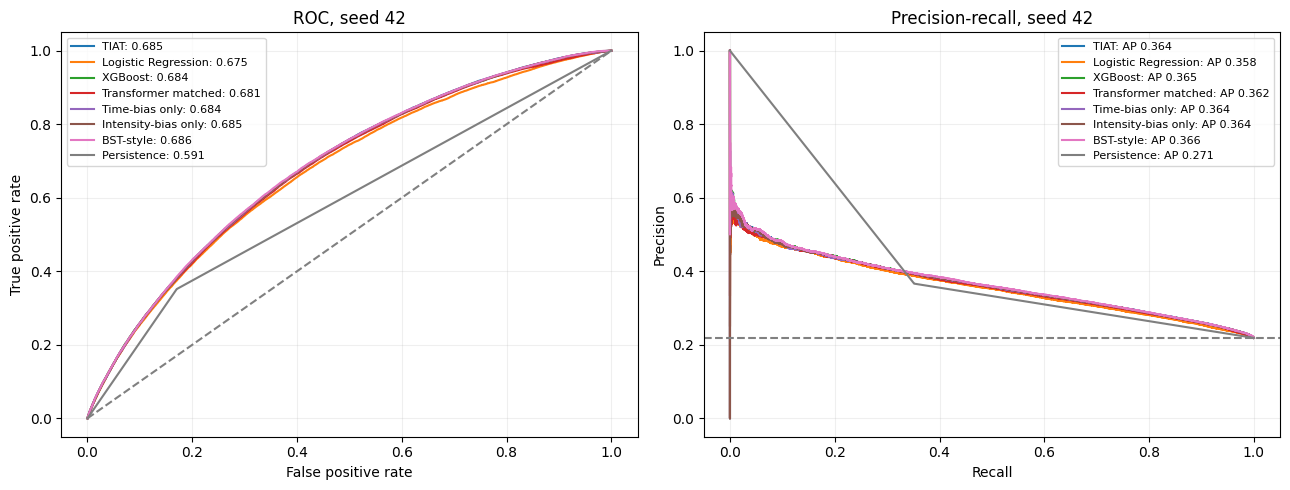

Hasil eksperimen tersimpan di: /content/drive/MyDrive/dataset/processed_tiat_review_v2/20261118T181035Z_71d30f19


In [ ]:
# SEL 17 - Kurva ROC, precision-recall, dan catatan lingkungan eksperimen
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
if len(np.unique(test['y'])) == 2:
    for (name, seed), probability in predictions.items():
        if seed != primary_seed:
            continue
        fpr, tpr, _ = roc_curve(test['y'], probability)
        precision, recall, _ = precision_recall_curve(test['y'], probability)
        axes[0].plot(fpr, tpr, label=f'{name}: {roc_auc_score(test["y"], probability):.3f}')
        axes[1].plot(recall, precision, label=f'{name}: AP {average_precision_score(test["y"], probability):.3f}')
    axes[0].plot([0, 1], [0, 1], '--', color='grey')
    axes[1].axhline(float(test['y'].mean()), linestyle='--', color='grey')
    axes[0].set(xlabel='False positive rate', ylabel='True positive rate', title=f'ROC, seed {primary_seed}')
    axes[1].set(xlabel='Recall', ylabel='Precision', title=f'Precision-recall, seed {primary_seed}')
    for ax in axes:
        ax.legend(fontsize=8)
        ax.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(RUN_DIR / 'roc_pr_comparison.png', dpi=180)
    plt.show()
else:
    plt.close(fig)
    print('Kurva ROC/PR tidak ditampilkan: test hanya memiliki satu kelas.')

import importlib.metadata
versions = {name: importlib.metadata.version(name)
            for name in ['numpy', 'pandas', 'scikit-learn', 'torch', 'xgboost', 'pyarrow']}
with open(RUN_DIR / 'environment.json', 'w') as f:
    json.dump({'python': sys.version, 'device': str(DEVICE), 'packages': versions,
               'cuda_available': torch.cuda.is_available()}, f, indent=2)
print('Hasil eksperimen tersimpan di:', RUN_DIR)